## Cel projektu: Predykcja odejść klientów (Customer Churn) w branży telekomunikacyjnej
Celem analizy jest identyfikacja kluczowych czynników wpływających na rezygnację klientów z usług telekomunikacyjnych (zbiór IBM Telco Customer Churn) oraz budowa modelu uczenia maszynowego potrafiącego z wyprzedzeniem wytypować klientów zagrożonych odejściem (Churn = 1). Z perspektywy biznesowej pozyskanie nowego klienta jest kilkukrotnie droższe niż utrzymanie obecnego, dlatego głównym priorytetem modelu jest wysoka czułość (Recall) dla klasy 1 oraz wysoka zdolność dyskryminacyjna mierzona polem pod krzywą ROC (ROC-AUC).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    accuracy_score, roc_auc_score, roc_curve
)

df = pd.read_csv('dane_ibm.csv')
#df.head()

In [22]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', '', regex=True))
df['TotalCharges'] = df['TotalCharges'].fillna(0)

col_to_cod_y_n = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
cod_map = {'Yes': 1, 'No': 0}

for col in col_to_cod_y_n:
    df[col] = df[col].map(cod_map)

display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,1,0,1,0,No phone service,DSL,No,...,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,0,0,2,1,No,DSL,Yes,...,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,0,0,45,0,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,0,0,2,1,No,Fiber optic,No,...,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


## Podział danych na zbiór treningowy i testowy
Zanim przystąpimy do Eksploracyjnej Analizy Danych i wizualizacji rozkładów, oddzielamy 20% danych (1409 klientów) jako niezależny zbiór testowy (test_df). Zastosowanie stratyfikacji (stratify=df['Churn']) gwarantuje zachowanie identycznej proporcji odejść w obu zbiorach. Od tego momentu wszelkie wykresy, wnioski oraz zależności badamy wyłącznie na zbiorze treningowym, aby wykluczyć wyciek informacji.

In [23]:

train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df['Churn']
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Zbiór treningowy: {train_df.shape[0]} klientów")
print(f"Zbiór testowy: {test_df.shape[0]} klientów")

Zbiór treningowy: 5634 klientów
Zbiór testowy: 1409 klientów


,Churn,customerID,ChurnRate,PopulationRate
Contract,,,,
Month-to-month,1326,3102,42.75,55.06
One year,130,1173,11.08,20.82
Two year,39,1359,2.87,24.12


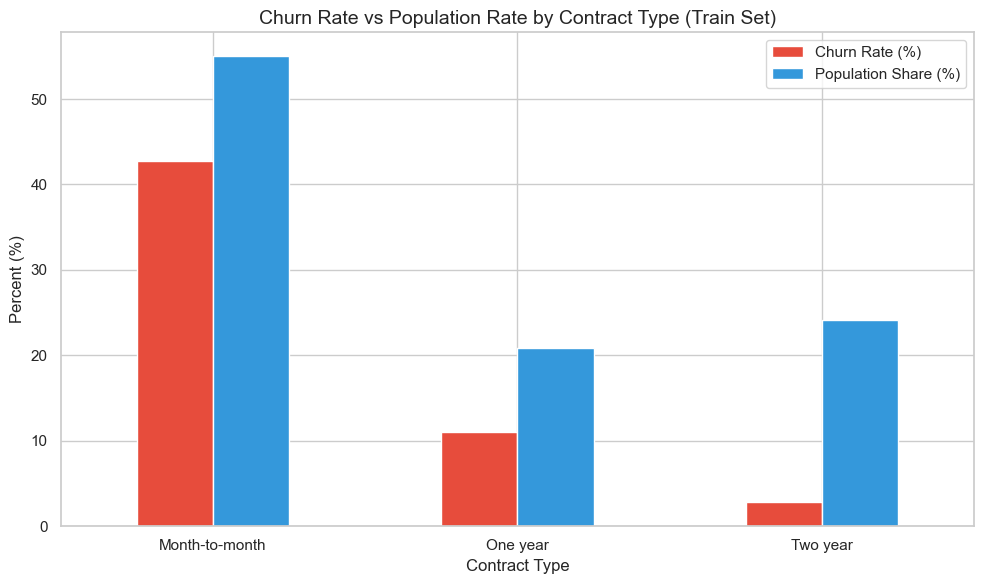

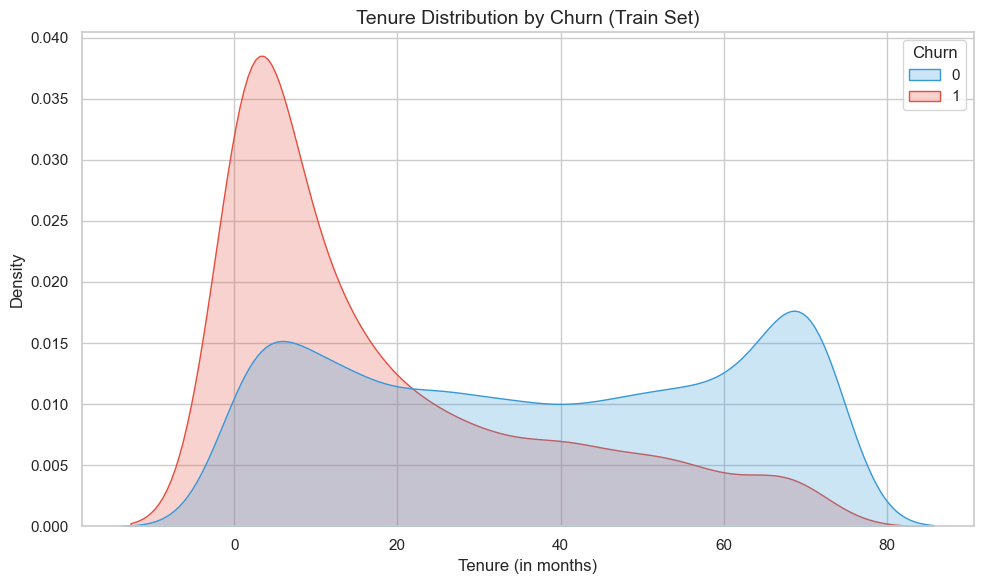

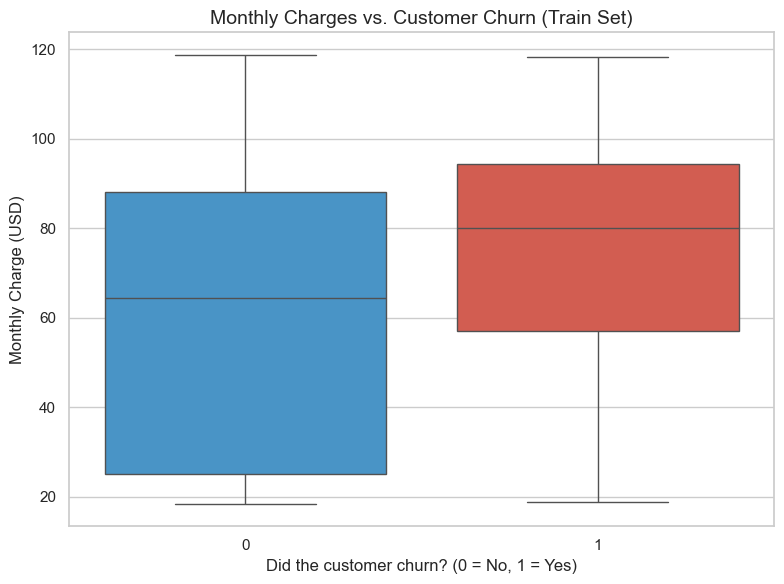

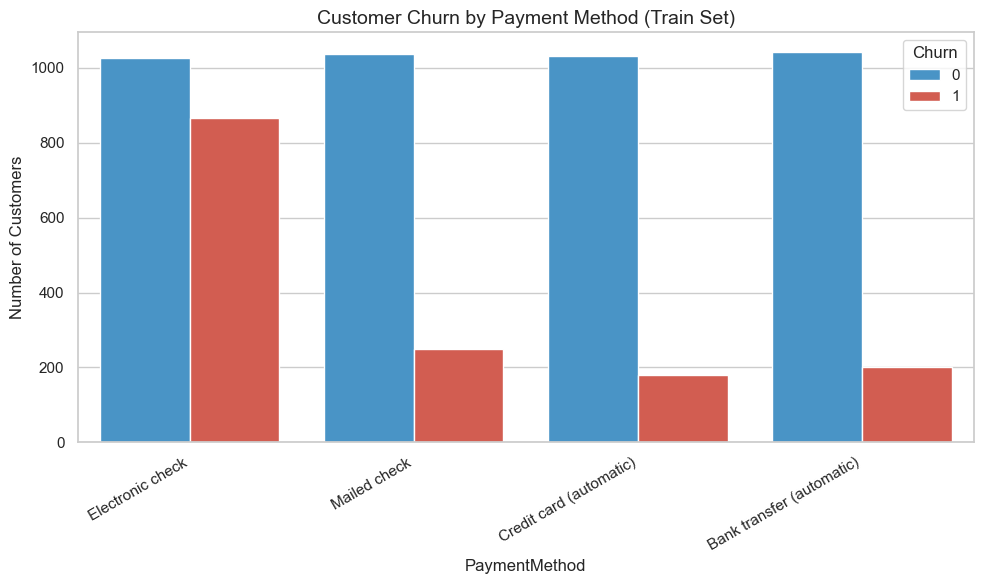

In [24]:
df_contract = train_df.groupby('Contract').agg({
    'Churn': 'sum',
    'customerID': 'count'
})
df_contract['ChurnRate'] = ((df_contract['Churn'] / df_contract['customerID']) * 100).round(2)
total_train_customers = train_df['customerID'].count()
df_contract['PopulationRate'] = ((df_contract['customerID'] / total_train_customers) * 100).round(2)
display(df_contract)

ax = df_contract[['ChurnRate', 'PopulationRate']].plot(kind='bar', figsize=(10, 6), color=['#e74c3c', '#3498db'])
ax.set_xticklabels(df_contract.index, rotation=0, ha='center')
plt.title('Churn Rate vs Population Rate by Contract Type (Train Set)', fontsize=14)
plt.ylabel('Percent (%)', fontsize=12)
plt.xlabel('Contract Type', fontsize=12)
plt.legend(['Churn Rate (%)', 'Population Share (%)'])
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))
sns.kdeplot(data=train_df, x='tenure', hue='Churn', fill=True, common_norm=False, palette=['#3498db', '#e74c3c'])
plt.title('Tenure Distribution by Churn (Train Set)', fontsize=14)
plt.xlabel('Tenure (in months)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))
sns.boxplot(data=train_df, x='Churn', y='MonthlyCharges', hue='Churn', palette=['#3498db', '#e74c3c'], legend=False)
plt.title('Monthly Charges vs. Customer Churn (Train Set)', fontsize=14)
plt.xlabel('Did the customer churn? (0 = No, 1 = Yes)')
plt.ylabel('Monthly Charge (USD)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(data=train_df, x='PaymentMethod', hue='Churn', palette=['#3498db', '#e74c3c'])
plt.title('Customer Churn by Payment Method (Train Set)', fontsize=14)
plt.xticks(rotation=30, ha='right')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

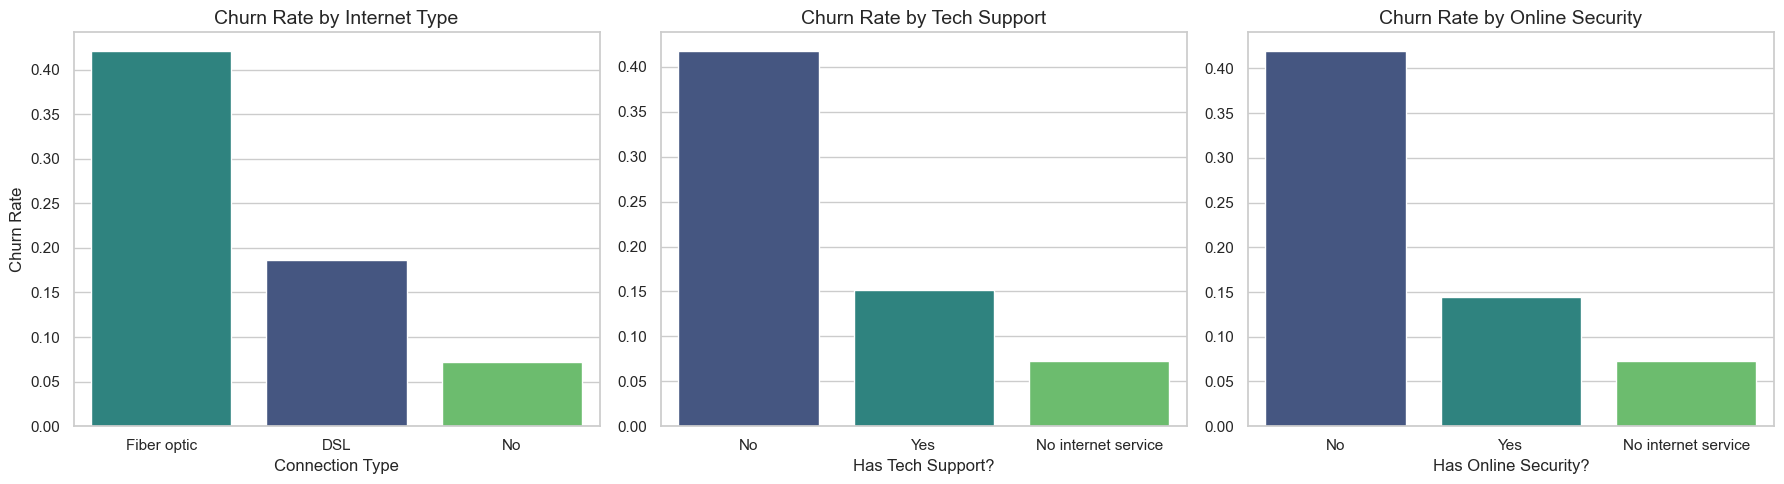

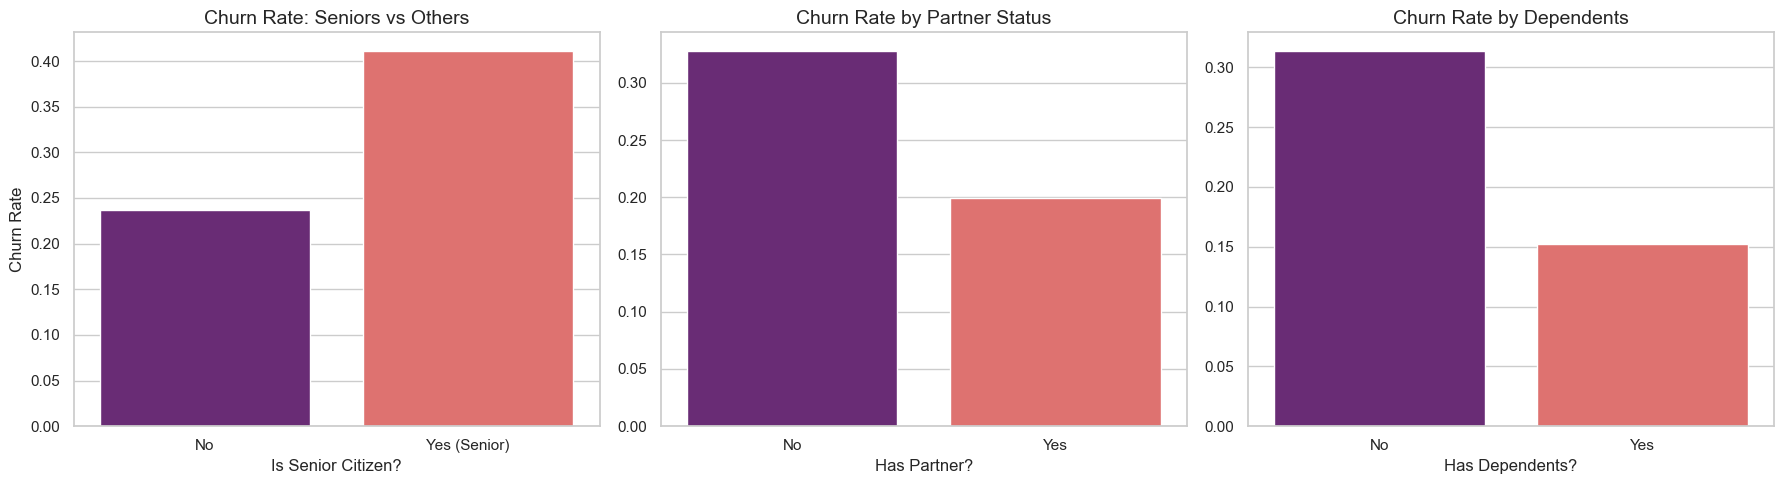

In [25]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order_internet = train_df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False).index
sns.barplot(data=train_df, x='InternetService', y='Churn', hue='InternetService', ax=axes[0], palette='viridis', errorbar=None, order=order_internet, legend=False)
axes[0].set_title('Churn Rate by Internet Type', fontsize=14)
axes[0].set_ylabel('Churn Rate')
axes[0].set_xlabel('Connection Type')

order_support = train_df.groupby('TechSupport')['Churn'].mean().sort_values(ascending=False).index
sns.barplot(data=train_df, x='TechSupport', y='Churn', hue='TechSupport', ax=axes[1], palette='viridis', errorbar=None, order=order_support, legend=False)
axes[1].set_title('Churn Rate by Tech Support', fontsize=14)
axes[1].set_ylabel('')
axes[1].set_xlabel('Has Tech Support?')

order_security = train_df.groupby('OnlineSecurity')['Churn'].mean().sort_values(ascending=False).index
sns.barplot(data=train_df, x='OnlineSecurity', y='Churn', hue='OnlineSecurity', ax=axes[2], palette='viridis', errorbar=None, order=order_security, legend=False)
axes[2].set_title('Churn Rate by Online Security', fontsize=14)
axes[2].set_ylabel('')
axes[2].set_xlabel('Has Online Security?')

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=train_df, x='SeniorCitizen', y='Churn', hue='SeniorCitizen', order=[0, 1], ax=axes[0], palette='magma', errorbar=None, legend=False)
axes[0].set_title('Churn Rate: Seniors vs Others', fontsize=14)
axes[0].set_ylabel('Churn Rate')
axes[0].set_xlabel('Is Senior Citizen?')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No', 'Yes (Senior)'])

sns.barplot(data=train_df, x='Partner', y='Churn', hue='Partner', order=[0, 1], ax=axes[1], palette='magma', errorbar=None, legend=False)
axes[1].set_title('Churn Rate by Partner Status', fontsize=14)
axes[1].set_ylabel('')
axes[1].set_xlabel('Has Partner?')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No', 'Yes'])

sns.barplot(data=train_df, x='Dependents', y='Churn', hue='Dependents', order=[0, 1], ax=axes[2], palette='magma', errorbar=None, legend=False)
axes[2].set_title('Churn Rate by Dependents', fontsize=14)
axes[2].set_ylabel('')
axes[2].set_xlabel('Has Dependents?')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['No', 'Yes'])

plt.tight_layout()
plt.show()

## Wnioski z analizy EDA:
Usługi internetowe (InternetService): Klienci korzystający ze światłowodu (Fiber optic) wykazują dramatycznie wyższy wskaźnik odejść (około 42%) w porównaniu do użytkowników łącza DSL (około 19%) oraz osób bez usługi internetowej (około 7%). Sugeruje to potencjalne problemy z ceną lub stabilnością oferty światłowodowej.   
Brak usług wsparcia i bezpieczeństwa (TechSupport oraz OnlineSecurity): Wśród klientów nieposiadających wsparcia technicznego (TechSupport = No) ani ochrony online (OnlineSecurity = No) odsetek odejść przekracza 41–42%. Posiadanie tych usług wiąże klienta z firmą i obniża ryzyko rezygnacji niemal trzykrotnie — do poziomu około 14–15%.   
Profil demograficzny (SeniorCitizen, Partner, Dependents): Seniorzy rezygnują z usług znacznie częściej (około 41%) niż pozostali klienci (około 23.5%). Z kolei osoby posiadające partnera (Partner = Yes, ~20% odejść vs ~33% u singli) oraz osoby mające dzieci/podopiecznych na utrzymaniu (Dependents = Yes, ~15% odejść vs ~31% u osób bez podopiecznych) są znacznie bardziej lojalne i rzadziej zmieniają operatora.

In [26]:
categorical_cols = [
    'gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 
    'StreamingMovies', 'Contract', 'PaymentMethod'
]


X_train = train_df.drop(columns=['customerID', 'Churn'])
y_train = train_df['Churn']

X_test = test_df.drop(columns=['customerID', 'Churn'])
y_test = test_df['Churn']


X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True, dtype=int)


X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)


X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train
)

print(f"Gotowa macierz X_train: {X_train.shape}")
print(f"Gotowa macierz X_test:  {X_test.shape}")

Gotowa macierz X_train: (5634, 30)
Gotowa macierz X_test:  (1409, 30)


In [27]:
rf_model = RandomForestClassifier(
    n_estimators=500, random_state=42, class_weight='balanced', n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("WYNIKI NA ZBIORZE TESTOWYM: RANDOM FOREST")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob_rf):.4f}\n")
print(classification_report(y_test, y_pred_rf))


neg_count = (y_tr == 0).sum()
pos_count = (y_tr == 1).sum()
scale_pos_weight = neg_count / pos_count

xgb_model = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    max_depth=4,
    learning_rate=0.03,
    n_estimators=1000,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=30
)

xgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=50)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("WYNIKI NA ZBIORZE TESTOWYM: XGBOOST")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob_xgb):.4f}\n")
print(classification_report(y_test, y_pred_xgb))

WYNIKI NA ZBIORZE TESTOWYM: RANDOM FOREST
Accuracy: 0.7857
ROC-AUC:  0.8261

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409

[0]	validation_0-logloss:0.68313
[50]	validation_0-logloss:0.51091
[100]	validation_0-logloss:0.48501
[150]	validation_0-logloss:0.47788
[200]	validation_0-logloss:0.47530
[250]	validation_0-logloss:0.47098
[283]	validation_0-logloss:0.47136
WYNIKI NA ZBIORZE TESTOWYM: XGBOOST
Accuracy: 0.7488
ROC-AUC:  0.8437

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted av

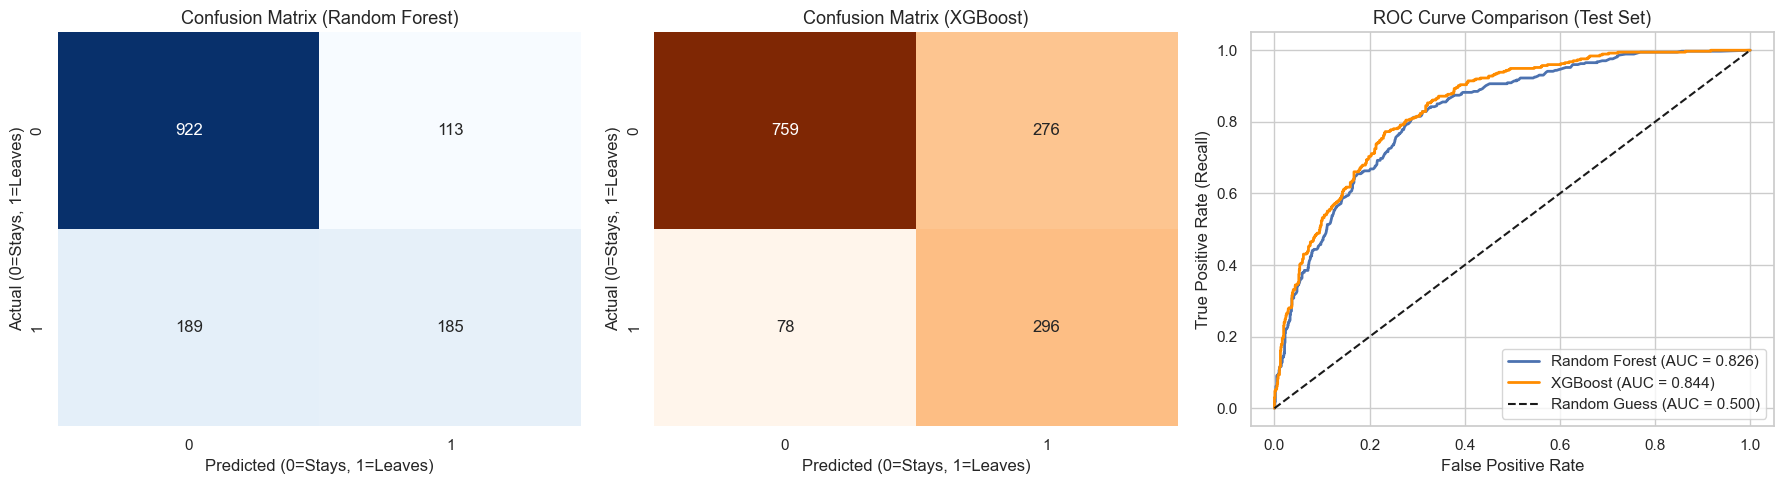

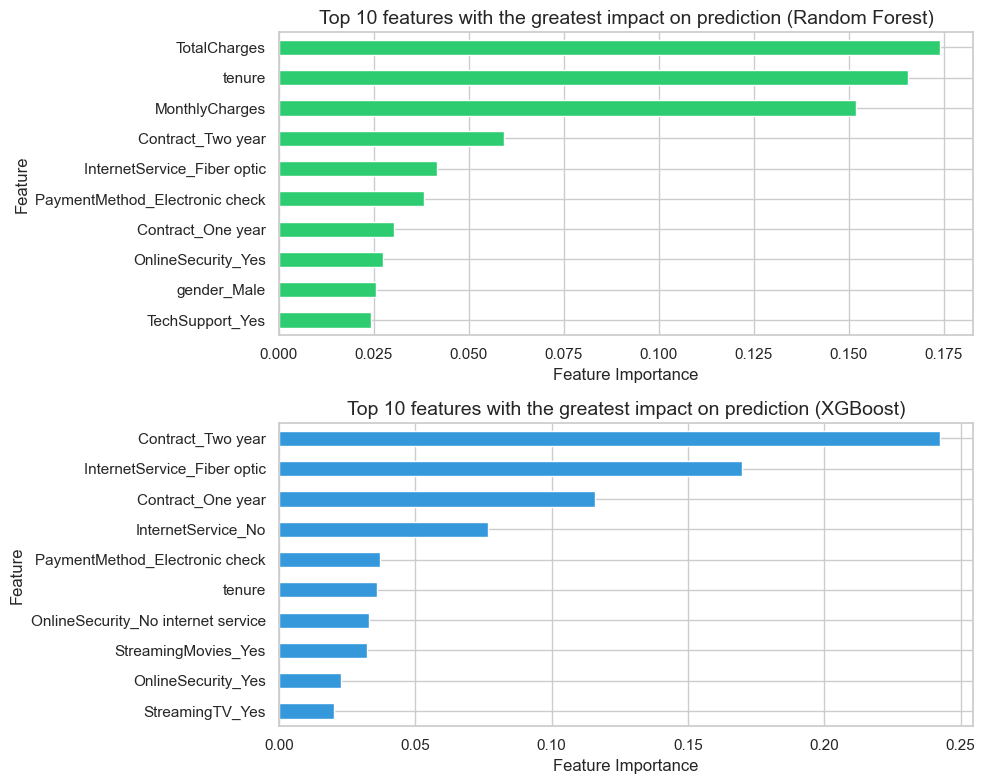

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Confusion Matrix (Random Forest)', fontsize=13)
axes[0].set_xlabel('Predicted (0=Stays, 1=Leaves)')
axes[0].set_ylabel('Actual (0=Stays, 1=Leaves)')

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1])
axes[1].set_title('Confusion Matrix (XGBoost)', fontsize=13)
axes[1].set_xlabel('Predicted (0=Stays, 1=Leaves)')
axes[1].set_ylabel('Actual (0=Stays, 1=Leaves)')

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

axes[2].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})", linewidth=2)
axes[2].plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})", linewidth=2, color='darkorange')
axes[2].plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.500)")
axes[2].set_title('ROC Curve Comparison (Test Set)', fontsize=13)
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate (Recall)')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

feature_importances_rf = pd.Series(rf_model.feature_importances_, index=X_train.columns)
feature_importances_xgb = pd.Series(xgb_model.feature_importances_, index=X_train.columns)

top_10_features_rf = feature_importances_rf.nlargest(10)
top_10_features_xgb = feature_importances_xgb.nlargest(10)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

top_10_features_rf.sort_values().plot(kind='barh', color='#2ecc71', ax=axes[0])
axes[0].set_title('Top 10 features with the greatest impact on prediction (Random Forest)', fontsize=14)
axes[0].set_xlabel('Feature Importance')
axes[0].set_ylabel('Feature')

top_10_features_xgb.sort_values().plot(kind='barh', color='#3498db', ax=axes[1])
axes[1].set_title('Top 10 features with the greatest impact on prediction (XGBoost)', fontsize=14)
axes[1].set_xlabel('Feature Importance')
axes[1].set_ylabel('Feature')

plt.tight_layout()
plt.show()

## Kluczowe wnioski matematyczne i biznesowe z projektu
**Dlaczego XGBoost wygrał z Random Forest mimo niższego Accuracy?**

W Random Forest głębokie drzewa decyzyjne (bez narzuconego limitu max_depth) dążą do czystych liści, 
przez co parametr class_weight='balanced' traci siłę oddziaływania. W efekcie Las Losowy pozostał zachowawczy: poprawnie sklasyfikował 922 klientów zostających w firmie, ale wykrył tylko 185 z 374 odchodzących klientów (Recall = 49%), przegapiając aż 189 rezygnacji (False Negatives).   

W modelu XGBoost połączenie płytkich drzew (max_depth=4), wczesnego zatrzymania oraz wagi scale_pos_weight przesunęło granicę decyzyjną na korzyść wyłapywania odejść. Model ten poprawnie zidentyfikował aż 296 z 374 odchodzących klientów (Recall = 79%), przepuszczając jedynie 78 przypadków. Choć odbyło się to kosztem większej liczby fałszywych alarmów (276 False Positives, co obniżyło Precision klasy 1 do 0.52 i ogólne Accuracy do 74.88%), to w realiach telekomunikacyjnych wysłanie kodu rabatowego lub wykonanie telefonu utrzymaniowego do 276 lojalnych klientów jest znacznie tańsze niż bezpowrotna utrata ponad 110 dodatkowych abonentów. Wyższość modelu XGBoost potwierdza również wyższe pole pod krzywą ROC (0.8437 vs 0.8261).   

Różnica w ważności cech (Feature Importance) pomiędzy modelami:
Random Forest (oparty na kryterium Giniego) przypisał największą wagę zmiennym ciągłym: TotalCharges, tenure oraz MonthlyCharges. Wynika to z matematycznej właściwości drzew losowych, które preferują cechy numeryczne o dużej liczbie unikalnych punktów podziału, a dopiero na kolejnych miejscach wskazują zmienne binarne (Contract_Two year, InternetService_Fiber optic, PaymentMethod_Electronic check).   
XGBoost (mierzący średni zysk informacyjny z podziału) jako najważniejsze predyktory wskazał strukturę umowy i typ usługi: kontrakt dwuletni (Contract_Two year — ważność ok. 0.24), internet światłowodowy (InternetService_Fiber optic — ok. 0.17) oraz kontrakt roczny (Contract_One year — ok. 0.115). Zmienne takie jak tenure czy płatność czekiem elektronicznym (PaymentMethod_Electronic check) pełnią w nim funkcję precyzyjnego doszczegółowienia ryzyka na niższych poziomach drzewa.   


Rekomendacje biznesowe dla operatora:
Konwersja umów miesięcznych na terminowe: Ponieważ długoterminowe kontrakty (Two year oraz One year) są najsilniejszym czynnikiem chroniącym przed odejściem w obu modelach, działania marketingowe powinny skupić się na oferowaniu zniżek za przejście z umowy miesięcznej na roczną po pierwszych 3–6 miesiącach stażu.   

Audyt usługi światłowodowej (Fiber optic) i dosprzedaż pakietów bezpieczeństwa: Ze względu na 42% wskaźnik odejść wśród użytkowników światłowodu oraz brakujących usług TechSupport i OnlineSecurity, firma powinna włączyć darmowy pakiet bezpieczeństwa/wsparcia technicznego na okres próbny do abonamentów Fiber optic.